# 🌱 Computer Vision — Real-World Data Preparation Project
### Session 05 | Student Assignment Notebook

**Project:** Prepare real bean-leaf images for a future CNN model  
**Final goal:** A clean, tested, model-ready image dataset — **no model training today**.

> **Project story:** An AgriTech team wants to build a system that can recognize healthy and diseased bean leaves. Your job is to inspect the real images, test image-processing ideas, and deliver reliable inputs for the ML engineer who will train the CNN.

---

### How to use this notebook

1. Read **Why this step matters** before running the code.
2. Run the starter examples to understand the data.
3. Complete every **🛠️ YOUR TASK** and `TODO` comment. **Do not skip code cells.**
4. Write short answers in **📝 Engineer's notes**. Explain your choice, not just the output.
5. Keep the original dataset unchanged while you experiment.
6. At the end, export your model-ready dataset and run the quality checks.

**Important:** This is a student starter notebook. Some functions intentionally raise `NotImplementedError` until you write your solution. That is part of your task.

## 🎯 Learning goals and project plan

By the end, you will be able to:

- Inspect a real image dataset and find possible quality problems.
- Explain pixels, channels, image shapes, and image data types.
- Convert images between RGB, Grayscale, Binary, and HSV.
- Use masks to select areas with a target color.
- Add *test noise* and compare Mean, Gaussian, and Median filters.
- Apply geometric transformations and explain when they help.
- Build one reusable preprocessing function.
- Keep **train**, **validation**, and **test** data separate and deliver arrays ready for a CNN.

| Stage | Your work | Expected output |
|---|---|---|
| 1 | Load and understand the data | Data overview |
| 2 | Data quality and EDA | Class counts, image examples, audit |
| 3 | Image types | RGB, Grayscale, Binary comparison |
| 4 | Color spaces | HSV channels and green masks |
| 5 | Image histogram | Brightness/contrast interpretation |
| 6 | Noise and filters | Visual and numeric comparison |
| 7 | Geometry and augmentation | Transformation gallery |
| 8 | Build the final preprocessing function | One tested function |
| 9 | Prepare and export the dataset | Arrays + labels + metadata |
| 10 | Quality checks and handoff | Final checklist + short report |

**Working rule:** Test ideas using copies of images. Do not permanently apply experimental noise, binary conversion, or green masks to your final CNN inputs.

## 0 — Setup: Prepare your workspace

### Why this step matters
A real project needs a clear environment, fixed settings, and repeatable results. If the team runs your notebook again, it should produce the same preprocessing steps.

**🛠️ YOUR TASK**
- Open this notebook in Google Colab or Jupyter.
- Run the installation cell once.
- Run the imports and configuration cells.
- Keep the random seed fixed.

In [1]:
# Step 0.1 — Install the required packages.
# In Google Colab, most of these packages may already exist.
%pip install -q datasets opencv-python-headless numpy pandas matplotlib pillow

In [2]:
# Step 0.2 — Import tools used during this project.
from datasets import load_dataset
from PIL import Image
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import json

# Set one fixed seed so random examples can be reproduced.
SEED = 42
rng = np.random.default_rng(SEED)

# We will use the same image size for the future CNN.
TARGET_SIZE = (224, 224)  # (width, height) for OpenCV
DATASET_ID = "AI-Lab-Makerere/beans"
EXPORT_DIR = Path("beans_model_ready")
EXPORT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Target image size:", TARGET_SIZE)

OpenCV version: 5.0.0
Target image size: (224, 224)


## 1 — Load the real dataset

### Why this step matters
Before cleaning any data, you must know **where it comes from**, **what the labels mean**, and **how the dataset is divided**. This protects you from using the wrong data or creating data leakage.

**Dataset:** [Beans dataset — Makerere AI Lab on Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans). It contains real bean-leaf images in three categories:

- `angular_leaf_spot`
- `bean_rust`
- `healthy`

It already provides `train`, `validation`, and `test` splits. **Keep those splits; do not merge them.** The first download needs internet access and may take a little while.

**🛠️ YOUR TASK**
1. Run the next cell and read the dataset structure.
2. Answer: What is one *feature*? What is a *label*?
3. Record how many images are in each split.

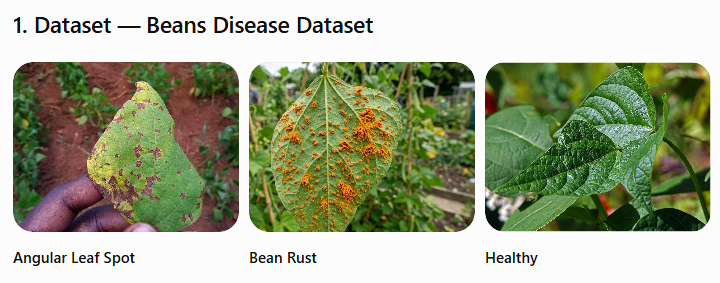

In [ ]:
# Step 1.1 — Load the dataset from Hugging Face.
# Note: the internet is needed the first time.
dataset = load_dataset(DATASET_ID)

print(dataset)
print("Available splits:", list(dataset.keys()))

# Read the class names from the dataset metadata, not by guessing.
CLASS_NAMES = dataset["train"].features["labels"].names
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
print("Class names:", CLASS_NAMES)
print("Class-to-ID mapping:", CLASS_TO_ID)

Example fields: dict_keys(['image_file_path', 'image', 'labels'])
Example label ID: 0
Example label name: angular_leaf_spot
Array shape: (500, 500, 3)
Array dtype: uint8


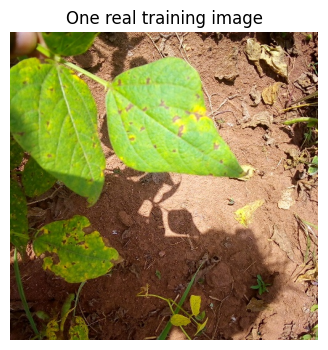

In [4]:
# Step 1.2 — Look at one example.
# Hugging Face image objects are usually decoded to PIL images.
example = dataset["train"][0]
print("Example fields:", example.keys())
print("Example label ID:", example["labels"])
print("Example label name:", CLASS_NAMES[example["labels"]])

# Convert to RGB to make the output predictable.
example_image = np.asarray(example["image"].convert("RGB"))
print("Array shape:", example_image.shape)
print("Array dtype:", example_image.dtype)

plt.figure(figsize=(5, 4))
plt.imshow(example_image)
plt.title("One real training image")
plt.axis("off")
plt.show()

**📝 Engineer's notes — Stage 1**

- **Input features:** `WRITE YOUR ANSWER`
- **Target label:** `WRITE YOUR ANSWER`
- **Number of images in train / validation / test:** `WRITE THE NUMBERS`
- **Why must we keep the test set separate?** `YOUR ANSWER`

**Checkpoint:** You understand what one row represents and what the future model should predict.

## 2 — Explore and audit the data (EDA)

### Why this step matters
A CNN cannot fix a broken dataset by itself. Before preprocessing, we need to know:

- Are some classes much larger than others?
- Do images have different sizes?
- Do we have unreadable images or unexpected image modes?
- Are labels clear and correctly mapped?

We will **inspect first**, then decide what processing is needed.

### Step 2.1 — Check class balance

**🛠️ YOUR TASK**

1. Count each class in each split.
2. Make a bar chart showing the class count in the **training** split.
3. Write a short observation: Is the training data balanced? Why does that matter?

**Hint:** `Counter(...)`, `CLASS_NAMES`, `plt.bar(...)`.

,split,class_name,count
0,train,angular_leaf_spot,345
1,train,bean_rust,348
2,train,healthy,341
3,validation,angular_leaf_spot,44
4,validation,bean_rust,45
5,validation,healthy,44
6,test,angular_leaf_spot,43
7,test,bean_rust,43
8,test,healthy,42


<BarContainer object of 3 artists>

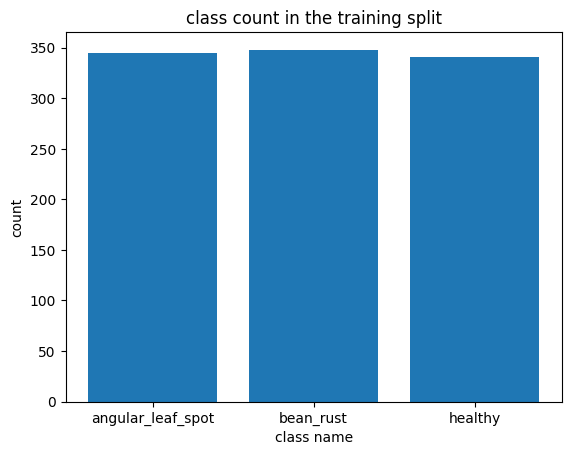

In [7]:
# Starter: create a small class-count table.
class_count_rows = []
for split_name, split_data in dataset.items():
    counts = Counter(split_data["labels"])
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_count_rows.append({
            "split": split_name,
            "class_name": class_name,
            "count": counts.get(class_id, 0),
        })

class_count_df = pd.DataFrame(class_count_rows)
display(class_count_df)

# TODO 2.1 — Make a bar chart using the TRAIN rows only.
train_counts = class_count_df[class_count_df["split"] == "train"]
plt.title('class count in the training split')
plt.xlabel('class name')
plt.ylabel('count')
plt.bar(train_counts["class_name"], train_counts["count"])
# Hint 1: train_counts = class_count_df[class_count_df["split"] == "train"]
# Hint 2: use plt.bar(train_counts["class_name"], train_counts["count"])
# Hint 3: add a title, axis labels, and readable class labels.

### Step 2.2 — Create an image gallery

### Why this step matters
Numbers do not show everything. A visual gallery helps us notice image quality, background changes, leaf position, and lighting conditions.

**🛠️ YOUR TASK**
- Show **9 random training images** in a 3×3 grid.
- Write each image's class name above it.
- Look for at least **two differences** between real images.

**Hint:** `rng.choice(...)`, `plt.subplots(3, 3)`, `axes.flat`, `imshow(...)`.

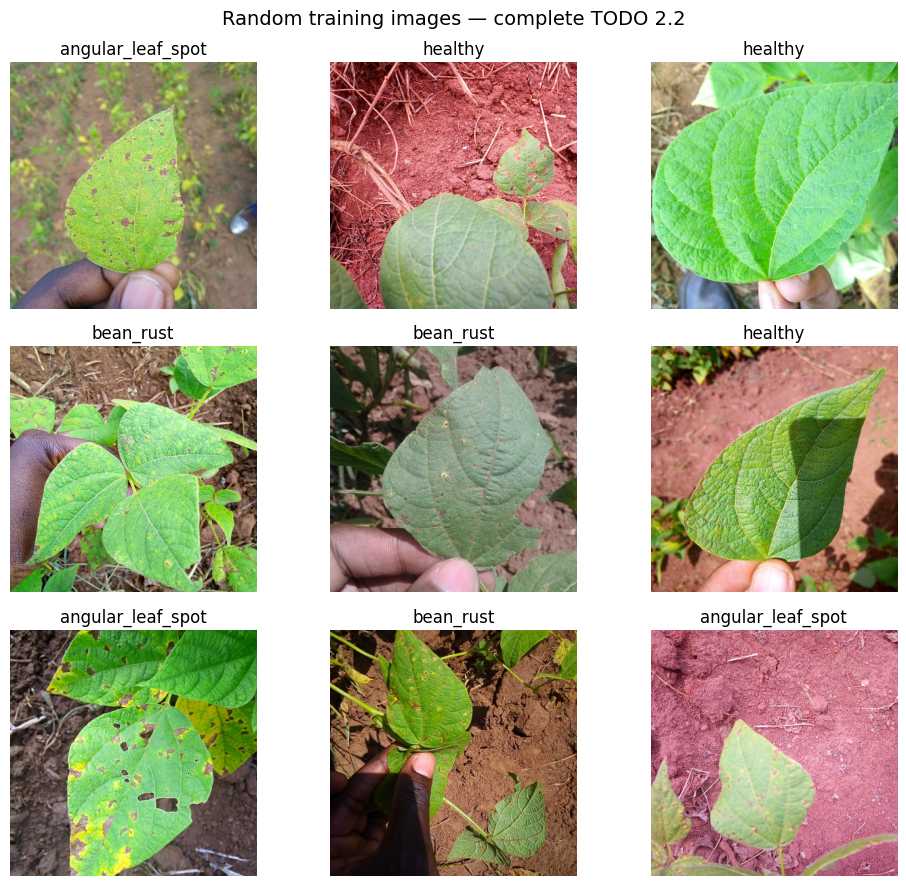

In [8]:
# TODO 2.2 — Fill the missing lines in this gallery.
random_indices = rng.choice(len(dataset["train"]), size=9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for axis, row_index in zip(axes.flat, random_indices):
    item = dataset["train"][int(row_index)]

    # TODO: convert the PIL image to a NumPy RGB array.
    image_array = np.asarray(item["image"].convert("RGB"))

    # TODO: show the image in this axis.
    axis.imshow(image_array)

    # TODO: show the correct class name as a title.
    axis.set_title(CLASS_NAMES[int(item["labels"])])

    axis.axis("off")

plt.suptitle("Random training images — complete TODO 2.2", fontsize=14)
plt.tight_layout()
plt.show()

### Step 2.3 — Inspect image sizes, channels, and modes

### Why this step matters
A batch of CNN inputs must have a consistent shape. Some image files might be RGB, grayscale, RGBA, or different sizes. We should **measure this before resizing**.

**🛠️ YOUR TASK**
- Review the table below.
- Report the minimum and maximum width and height.
- Check if there are images that are not RGB.
- Explain what can go wrong if we stack different image sizes directly.

,split,index,width,height,mode,label
0,train,0,500,500,RGB,angular_leaf_spot
1,train,1,500,500,RGB,angular_leaf_spot
2,train,2,500,500,RGB,angular_leaf_spot
3,train,3,500,500,RGB,angular_leaf_spot
4,train,4,500,500,RGB,angular_leaf_spot


'\nImage size summary:\n'

,width,height
count,1295.0,1295.0
mean,500.0,500.0
std,0.0,0.0
min,500.0,500.0
25%,500.0,500.0
50%,500.0,500.0
75%,500.0,500.0
max,500.0,500.0


'\nImage mode counts:\n'

,count
mode,
RGB,1295


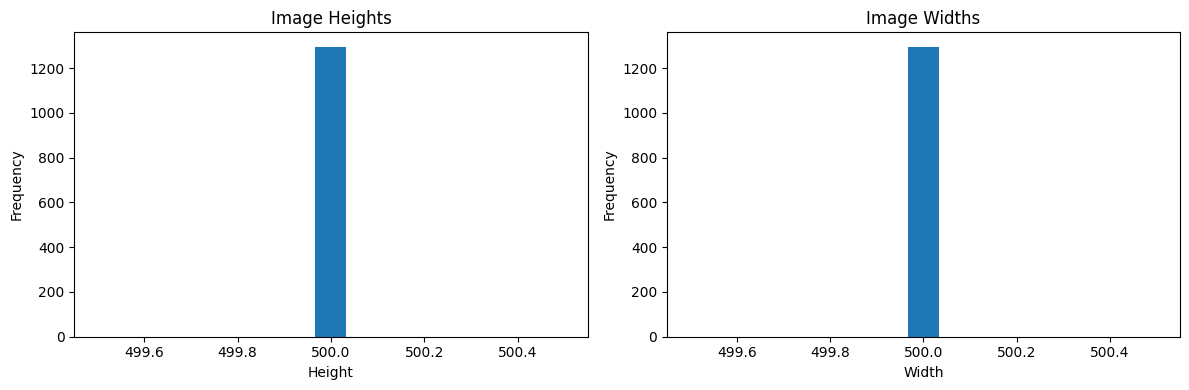

In [15]:
# This is a data audit, so it is OK to scan all split metadata.
image_audit = []
for split_name, split_data in dataset.items():
    for image_index, row in enumerate(split_data):
        pil_img = row["image"]
        image_audit.append({
            "split": split_name,
            "index": image_index,
            "width": pil_img.width,
            "height": pil_img.height,
            "mode": pil_img.mode,
            "label": CLASS_NAMES[int(row["labels"])],
        })

audit_df = pd.DataFrame(image_audit)
display(audit_df.head())
display("\nImage size summary:\n", audit_df[["width", "height"]].describe())
display("\nImage mode counts:\n", audit_df["mode"].value_counts())

# TODO 2.3 — Plot image widths OR heights as a histogram.
plt.figure(figsize=(12, 4))

# Heights
plt.subplot(1, 2, 1)
plt.title('Image Heights')
plt.hist(audit_df["height"], bins=15)
plt.xlabel("Height")
plt.ylabel("Frequency")

# Widths
plt.subplot(1, 2, 2)
plt.title('Image Widths')
plt.hist(audit_df["width"], bins=15)
plt.xlabel("Width")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
# Hint: plt.hist(audit_df["width"], bins=15)

### Step 2.4 — Find unreadable or invalid images

### Why this step matters
If one file is broken, your full preprocessing job may stop in the middle. A reliable engineering pipeline checks input quality and records problems.

**🛠️ YOUR TASK**
- Try to decode every image.
- Find empty images or unexpected arrays.
- Keep a list of issues (split, row, error).
- Do not silently delete a bad image. Explain the decision.

**Hint:** `try/except`, `np.asarray(...)`, `array.size`, `np.isfinite(...)`.

In [16]:

def audit_split_images(split_data, split_name):
    """Return a list of problems found while checking images."""
    issues = []

    for index in range(len(split_data)):
        try:
            # Read and convert image to RGB
            image = split_data[index]["image"].convert("RGB")

            # Convert to NumPy array
            image_array = np.asarray(image)

            # Check image integrity
            if (
                image_array.size == 0
                or image_array.ndim != 3
                or image_array.shape[2] != 3
            ):
                issues.append({
                    "split": split_name,
                    "index": index,
                    "error": "Invalid image shape or empty image"
                })

        except Exception as error:
            issues.append({
                "split": split_name,
                "index": index,
                "error": str(error)
            })

    return issues


# Run the checker on all splits
all_issues = []

for split_name in dataset.keys():
    all_issues.extend(
        audit_split_images(dataset[split_name], split_name)
    )

print("Number of issues:", len(all_issues))
display(pd.DataFrame(all_issues).head())


Number of issues: 0


""


**📝 Engineer's notes — Stage 2**

- **Class distribution:** `YOUR OBSERVATION`
- **Image sizes / modes:** `YOUR OBSERVATION`
- **Data quality issues found:** `YOUR OBSERVATION`
- **One risk for the future CNN:** `YOUR ANSWER`

**Checkpoint:** You have a short, evidence-based data quality report.

## 3 — Understand image types: RGB, Grayscale, Binary

### Why this step matters
Images are numbers. Different image types hold different information:

- **RGB:** Three color channels. Often useful for recognizing plant diseases.
- **Grayscale:** One intensity channel. Useful for understanding shapes, edges, and brightness.
- **Binary:** Two possible states. Useful for simple masks and threshold-based segmentation.

**Important:** For our final CNN, we plan to keep **RGB**. The following conversions are learning experiments, **not** final training-data replacements.

### Step 3.1 — Inspect one RGB pixel

**🛠️ YOUR TASK**
- Select a training image.
- Print its shape and one pixel's RGB values.
- Find its minimum and maximum pixel values.
- Explain what the three values represent.

In [20]:
# Use the same sample to compare the image types.
selected_row = dataset["train"][15]
rgb_image = np.asarray(selected_row["image"].convert("RGB"))

print("RGB shape:", rgb_image.shape)
print("RGB dtype:", rgb_image.dtype)
print("Top-left pixel:", rgb_image[0, 0])

# TODO 3.1 — Print the min and max pixel values.
print(f'Max: {rgb_image.max()}')
print(f'Min: {rgb_image.min()}')
# TODO 3.1 — Print the Red, Green, Blue values of one pixel separately.
print(f'Red: {rgb_image[0, 0, 0]}')
print(f'Green: {rgb_image[0, 0, 1]}')
print(f'Blue: {rgb_image[0, 0, 2]}')

RGB shape: (500, 500, 3)
RGB dtype: uint8
Top-left pixel: [127 145  23]
Max: 255
Min: 0
Red: 127
Green: 145
Blue: 23


### Step 3.2 — Convert RGB to Grayscale

### Why this step matters
Grayscale removes color channels and keeps brightness information. It makes some image-processing algorithms simpler, but it also removes information that may be helpful to the CNN.

**🛠️ YOUR TASK**
- Convert the RGB image to Grayscale.
- Print its new shape.
- Plot RGB and Grayscale images next to each other.

**Hint:** `cv2.COLOR_RGB2GRAY` (do **not** use `COLOR_BGR2GRAY` here, because your NumPy image is RGB).

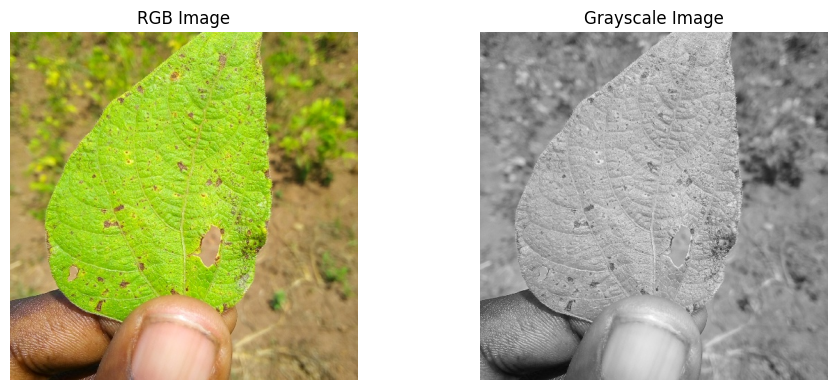

Grayscale shape: (500, 500)


In [21]:
# Convert RGB to Grayscale
gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)

# Plot RGB and Grayscale side by side
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Print Grayscale shape
print("Grayscale shape:", gray_image.shape)

### Step 3.3 — Convert Grayscale to Binary

### Why this step matters
Thresholding is a simple way to separate bright and dark parts. It produces a binary result. This does **not** automatically identify sick leaves; it only checks a value against a threshold.

**🛠️ YOUR TASK**
- Use a threshold of **127**.
- Show Original RGB, Grayscale, and Binary in one row.
- Try a second threshold, such as **180**.
- Explain what changed.

**Hint:** `cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)`.

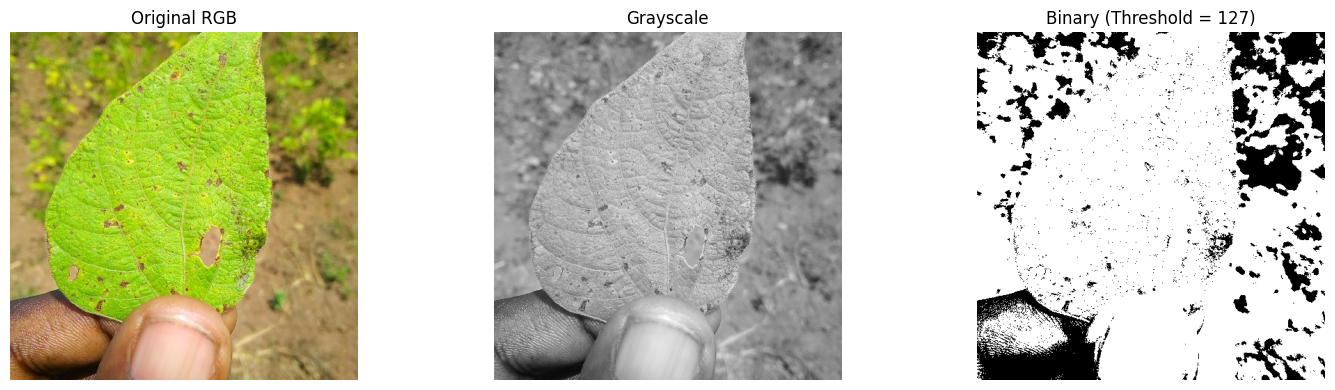

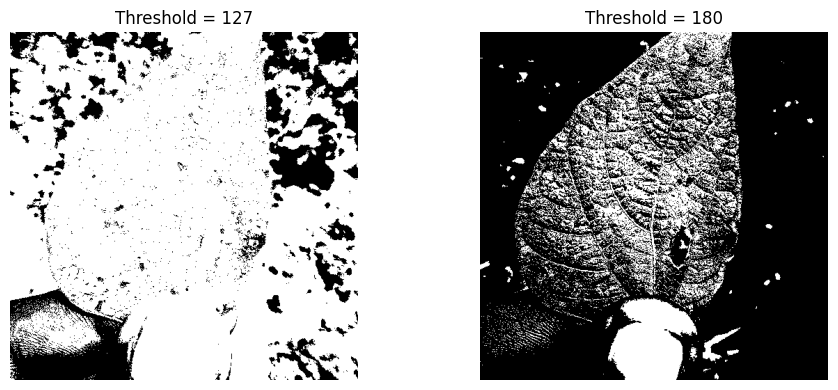

In [22]:

# First threshold
threshold_value = 127

_, binary_image_127 = cv2.threshold(
    gray_image,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

# Second threshold
threshold_value = 180

_, binary_image_180 = cv2.threshold(
    gray_image,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

# Plot RGB, Grayscale, and Binary (Threshold = 127)
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary_image_127, cmap="gray", vmin=0, vmax=255)
plt.title("Binary (Threshold = 127)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Compare the two binary thresholds
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(binary_image_127, cmap="gray", vmin=0, vmax=255)
plt.title("Threshold = 127")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image_180, cmap="gray", vmin=0, vmax=255)
plt.title("Threshold = 180")
plt.axis("off")

plt.tight_layout()
plt.show()


**📝 Engineer's notes — Stage 3**

- **What information is lost after converting RGB to Grayscale?** `YOUR ANSWER`
- **What does a white pixel mean in your Binary output?** `YOUR ANSWER`
- **Which image type should we keep for the final plant disease CNN? Why?** `YOUR ANSWER`

## 4 — Explore color spaces: RGB and HSV

### Why this step matters
RGB stores colors using red, green, and blue intensities. HSV separates **Hue** (color family), **Saturation** (color purity), and **Value** (brightness). This can make color selection easier.

For 8-bit images, OpenCV's standard HSV format commonly uses:

| Channel | Range |
|---|---|
| H | 0–179 |
| S | 0–255 |
| V | 0–255 |

**Critical detail:** `cv2.cvtColor` needs the correct input color order. Our array is **RGB**, so use `COLOR_RGB2HSV`.

### Step 4.1 — Convert and inspect HSV channels

**🛠️ YOUR TASK**
- Convert an RGB bean image to HSV.
- Extract H, S, and V channels.
- Show the original RGB image and the three channels in a 2×2 grid.
- Print the value range in each channel.

HSV shape: (500, 500, 3)


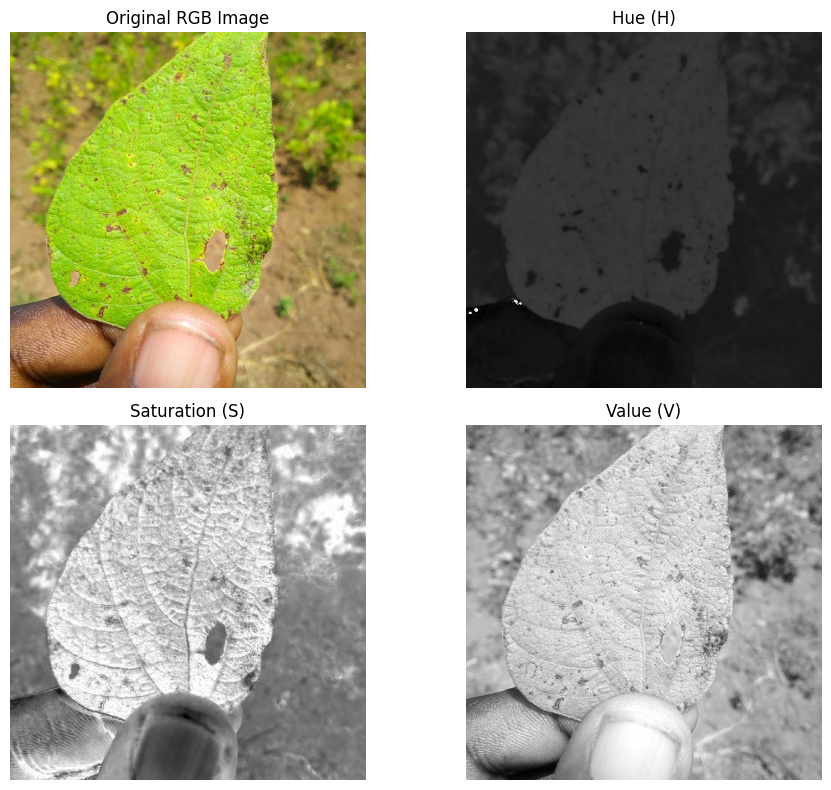

Hue range: 0 - 179
Saturation range: 2 - 255
Value range: 10 - 255


In [23]:

# One line is provided so you can focus on channel analysis.
hsv_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)
print("HSV shape:", hsv_image.shape)

# TODO 4.1 — Extract H, S, V channels using hsv_image[:, :, channel_index].
h_channel = hsv_image[:, :, 0]
s_channel = hsv_image[:, :, 1]
v_channel = hsv_image[:, :, 2]

# TODO 4.1 — Plot the RGB image and the H, S, V channels.
# Hint: display single channels with cmap="gray" and add clear titles.

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(rgb_image)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(h_channel, cmap="gray")
plt.title("Hue (H)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(s_channel, cmap="gray")
plt.title("Saturation (S)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(v_channel, cmap="gray")
plt.title("Value (V)")
plt.axis("off")

plt.tight_layout()
plt.show()

# TODO 4.1 — Print min/max for each of the three channels.
print("Hue range:", h_channel.min(), "-", h_channel.max())
print("Saturation range:", s_channel.min(), "-", s_channel.max())
print("Value range:", v_channel.min(), "-", v_channel.max())


### Step 4.2 — Create a green color mask

### Why this step matters
We can ask: "Which pixels look green?" A mask shows pixels inside a chosen color range. This is useful for understanding color segmentation, but a green region is **not** the same as a healthy leaf.

**🛠️ YOUR TASK**
1. Choose a reasonable lower and upper HSV range for green.
2. Make a binary mask using `cv2.inRange`.
3. Apply the mask to the RGB image using `cv2.bitwise_and`.
4. Show **Original / Mask / Masked RGB** side by side.
5. Adjust the limits if the mask includes too much background.

**Hint:** Start by experimenting with an H range near **35–85**, then choose S and V limits from **0–255**. These are starting points, not universal truth.

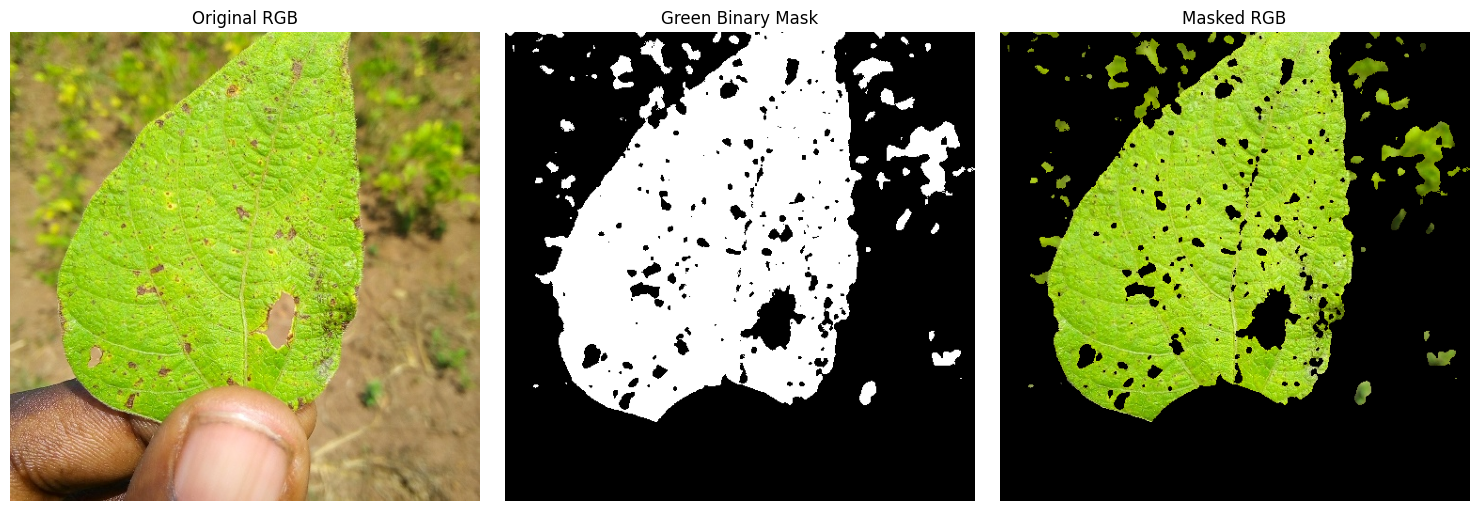

Green pixels percentage: 38.84%


In [24]:
# TODO 4.2 — Replace None with two 3-element uint8 arrays: [H, S, V].
lower_green = np.array([35, 40, 40], dtype=np.uint8)
upper_green = np.array([85, 255, 255], dtype=np.uint8)

# Create binary mask
mask = cv2.inRange(hsv_image, lower_green, upper_green)

# Apply mask to the original RGB image
masked_rgb = cv2.bitwise_and(rgb_image, rgb_image, mask=mask)

# TODO: plot original RGB image, binary mask, and masked image.
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Green Binary Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(masked_rgb)
plt.title("Masked RGB")
plt.axis("off")

plt.tight_layout()
plt.show()

# TODO: calculate percentage of image pixels selected by the mask.
green_percentage = np.mean(mask > 0) * 100
print(f"Green pixels percentage: {green_percentage:.2f}%")

### Step 4.3 — Compare green masks across classes

**🛠️ YOUR TASK**
- Choose one image from **healthy**, one from **bean_rust**, and one from **angular_leaf_spot**.
- Apply the **same HSV bounds** to all three images.
- Make a comparison chart.
- Answer: Can a green mask alone tell us the disease class? What is its limitation?

**Hint:** Use `CLASS_TO_ID` to find examples from each class; use `next(...)` or filter indices.

Found class examples: ['angular_leaf_spot', 'bean_rust', 'healthy']
healthy: 68.90% green pixels
bean_rust: 35.95% green pixels
angular_leaf_spot: 25.67% green pixels


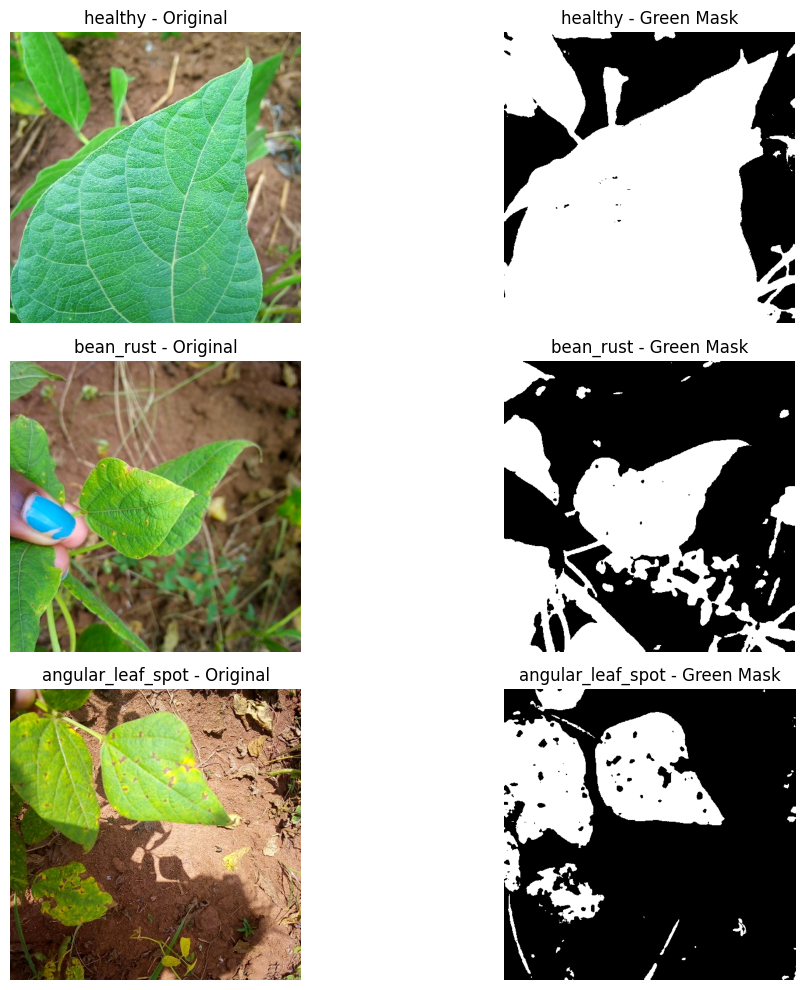

In [25]:

# TODO 4.3 — Create a small gallery of 3 classes using one shared green mask.

# Starter: collect one row for each label from TRAIN only.
class_examples = {}

for row in dataset["train"]:
    label_id = int(row["labels"])

    if label_id not in class_examples:
        class_examples[label_id] = row

    if len(class_examples) == len(CLASS_NAMES):
        break

print("Found class examples:", [CLASS_NAMES[i] for i in class_examples])

# Select the required classes
target_classes = ["healthy", "bean_rust", "angular_leaf_spot"]

# TODO: for each class, convert RGB -> HSV -> binary mask.
# TODO: show original and mask, with class names.

plt.figure(figsize=(12, 10))

for index, class_name in enumerate(target_classes):

    # Get class ID
    class_id = CLASS_TO_ID[class_name]

    # Get one example from this class
    example = class_examples[class_id]

    # Convert PIL image to RGB NumPy array
    image = np.asarray(example["image"].convert("RGB"))

    # Convert RGB to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Apply the same green mask bounds from Step 4.2
    mask = cv2.inRange(hsv, lower_green, upper_green)

    # Calculate percentage of selected pixels
    green_percentage = np.mean(mask > 0) * 100

    # Plot original image
    plt.subplot(3, 2, index * 2 + 1)
    plt.imshow(image)
    plt.title(f"{class_name} - Original")
    plt.axis("off")

    # Plot binary mask
    plt.subplot(3, 2, index * 2 + 2)
    plt.imshow(mask, cmap="gray")
    plt.title(f"{class_name} - Green Mask")
    plt.axis("off")

    print(f"{class_name}: {green_percentage:.2f}% green pixels")

plt.tight_layout()
plt.show()


**📝 Engineer's notes — Stage 4**

- **My green HSV range:** `YOUR VALUES`
- **Why did I choose this range?** `YOUR ANSWER`
- **One reason a color mask may fail:** `YOUR ANSWER`
- **Should the final CNN receive the mask or the RGB image? Explain.** `YOUR ANSWER`

## 6 — Test noise and filters (controlled experiment)

### Why this step matters
Real photos may contain sensor noise, compression artifacts, or poor lighting. Filters can reduce noise, but can also remove disease details. In this experiment, you will **add known noise to a copy** and measure how well each filter recovers the clean image.

**Safety rule for the dataset:** This is an experiment only. **Do not replace the original data with noisy or filtered images** in the final dataset unless you have tested and justified it.

### Step 6.1 — Create two noisy copies

**🛠️ YOUR TASK**

1. Write `add_gaussian_noise(image, sigma, seed)`.
2. Write `add_salt_pepper_noise(image, amount, seed)`.
3. Show clean, Gaussian-noisy, and Salt-and-Pepper-noisy versions side by side.

**Hint for Gaussian:** sample random values with `rng.normal(...)`, add to a **float** copy, clip to `[0,255]`, convert back to `uint8`.

**Hint for Salt-and-Pepper:** choose random pixel positions; set some to black (`0`) and some to white (`255`). If your image has three channels, set all three values for each selected pixel.

Keep the functions reusable — they should work with any RGB image.

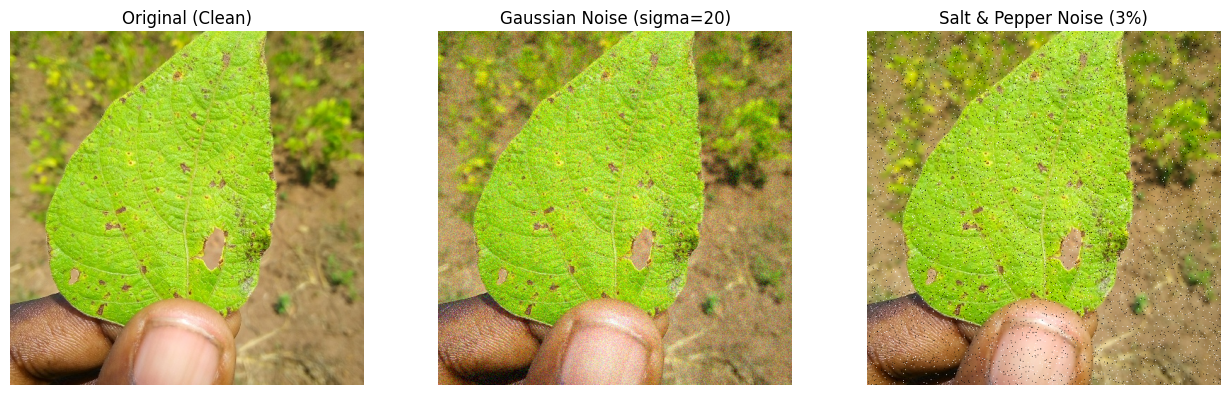

In [26]:

# TODO 6.1 — Complete both functions.
def add_gaussian_noise(image, sigma=20, seed=42):
    """Return a NEW uint8 image with Gaussian noise.

    Args:
        image: RGB NumPy image with dtype uint8.
        sigma: standard deviation of added noise.
        seed: makes the experiment repeatable.
    """
    # TODO: create local_rng = np.random.default_rng(seed)
    local_rng = np.random.default_rng(seed)

    # TODO: create normally distributed noise with the image's shape
    noise = local_rng.normal(0, sigma, image.shape)

    # TODO: add to a float copy, clip to 0..255, return uint8
    noisy_image = image.astype(np.float32) + noise
    noisy_image = np.clip(noisy_image, 0, 255)

    return noisy_image.astype(np.uint8)


def add_salt_pepper_noise(image, amount=0.03, seed=42):
    """Return a NEW uint8 image with salt-and-pepper noise.

    amount: fraction of pixel locations to change.
    """
    # TODO: image.copy() to protect the original
    noisy_image = image.copy()

    # TODO: use random row/column positions to select pixels
    local_rng = np.random.default_rng(seed)

    height, width = image.shape[:2]
    num_pixels = int(amount * height * width)

    rows = local_rng.integers(0, height, num_pixels)
    cols = local_rng.integers(0, width, num_pixels)

    # TODO: make some pixels black and the others white
    half = num_pixels // 2

    noisy_image[rows[:half], cols[:half]] = 0
    noisy_image[rows[half:], cols[half:]] = 255

    return noisy_image


# Step 6.1 test — Run after completing both functions.
clean_rgb = rgb_image.copy()

gaussian_noisy = add_gaussian_noise(
    clean_rgb, sigma=20, seed=SEED
)

salt_pepper_noisy = add_salt_pepper_noise(
    clean_rgb, amount=0.03, seed=SEED
)

# Check that your functions did not change the original image.
assert np.array_equal(clean_rgb, rgb_image), "You changed the original image!"

# TODO: plot the 3 images with useful titles.
# Hint: plt.subplots(1, 3, figsize=(13, 4))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(clean_rgb)
axes[0].set_title("Original (Clean)")
axes[0].axis("off")

axes[1].imshow(gaussian_noisy)
axes[1].set_title("Gaussian Noise (sigma=20)")
axes[1].axis("off")

axes[2].imshow(salt_pepper_noisy)
axes[2].set_title("Salt & Pepper Noise (3%)")
axes[2].axis("off")

plt.tight_layout()
plt.show()
